# Solution: Customer Churn Prediction

This notebook demonstrates a complete end-to-end classification workflow for the customer churn dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

from pathlib import Path

path = Path("data/customer_churn.csv")

In [2]:
df = pd.read_csv(path)

In [3]:
df.shape
df.head()
df.info()
df.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         1500 non-null   str    
 1   age                 1500 non-null   int64  
 2   gender              1500 non-null   str    
 3   region              1500 non-null   str    
 4   contract_type       1500 non-null   str    
 5   tenure_months       1500 non-null   int64  
 6   monthly_charges     1439 non-null   float64
 7   support_calls       1406 non-null   float64
 8   satisfaction_score  1398 non-null   float64
 9   online_banking      1500 non-null   bool   
 10  email_opt_in        1500 non-null   bool   
 11  new_customer        1500 non-null   bool   
 12  num_products        1500 non-null   int64  
 13  churn               1500 non-null   int64  
dtypes: bool(3), float64(3), int64(4), str(4)
memory usage: 133.4 KB


customer_id             0
age                     0
gender                  0
region                  0
contract_type           0
tenure_months           0
monthly_charges        61
support_calls          94
satisfaction_score    102
online_banking          0
email_opt_in            0
new_customer            0
num_products            0
churn                   0
dtype: int64

In [4]:
df = df.drop(columns=["customer_id"])
for column in ["monthly_charges", "satisfaction_score", "support_calls"]:
    median_value = df[column].median()
    df[column] = df[column].fillna(median_value)
for column in ["online_banking", "email_opt_in"]:
    mode_value = df[column].mode()[0]
    df[column] = df[column].fillna(mode_value)
df["online_banking"] = df["online_banking"].astype(int)
df["email_opt_in"] = df["email_opt_in"].astype(int)
df["gender"] = df["gender"].fillna(df["gender"].mode()[0])
df["region"] = df["region"].fillna(df["region"].mode()[0])
df["contract_type"] = df["contract_type"].fillna(df["contract_type"].mode()[0])
df.isna().sum()

age                   0
gender                0
region                0
contract_type         0
tenure_months         0
monthly_charges       0
support_calls         0
satisfaction_score    0
online_banking        0
email_opt_in          0
new_customer          0
num_products          0
churn                 0
dtype: int64

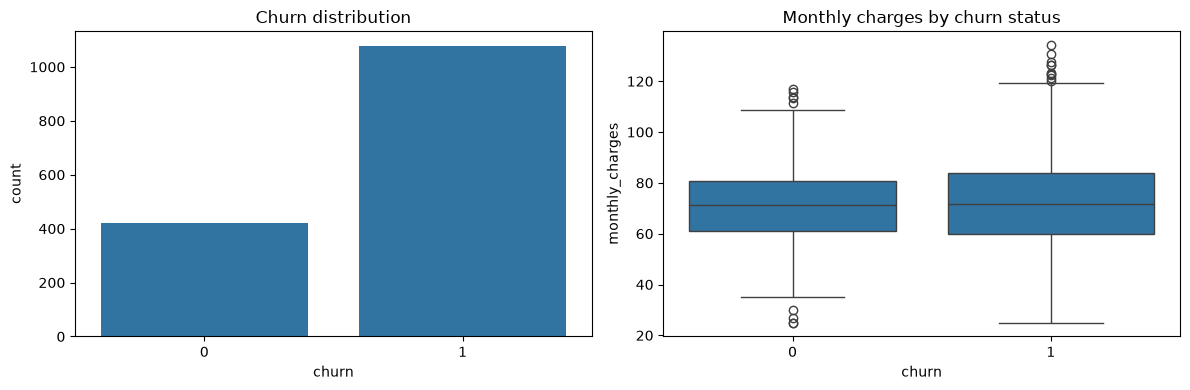

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="churn", ax=axes[0])
axes[0].set_title("Churn distribution")

sns.boxplot(data=df, x="churn", y="monthly_charges", ax=axes[1])
axes[1].set_title("Monthly charges by churn status")
plt.tight_layout()

In [6]:
feature_frame = df.drop(columns=["churn"])
numeric_features = feature_frame.select_dtypes(include=[np.number]).columns
categorical_features = feature_frame.select_dtypes(exclude=[np.number]).columns

X = feature_frame
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train.shape, X_test.shape

((1200, 12), (300, 12))

In [7]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced"))
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['age','gender','region',...,'email_opt_in','new_customer','num_products']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'

In [8]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

print(f"Accuracy: {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1 score: {f1:.3f}")
print(f"ROC AUC: {roc_auc:.3f}")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.743
Precision: 0.833
Recall: 0.806
F1 score: 0.819
ROC AUC: 0.770
[[ 49  35]
 [ 42 174]]
              precision    recall  f1-score   support

           0       0.54      0.58      0.56        84
           1       0.83      0.81      0.82       216

    accuracy                           0.74       300
   macro avg       0.69      0.69      0.69       300
weighted avg       0.75      0.74      0.75       300



In [9]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importances = model.named_steps["classifier"].feature_importances_
ranking = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)
ranking.head(10)

,feature,importance
1,num__tenure_months,0.179614
2,num__monthly_charges,0.146180
0,num__age,0.139446
4,num__satisfaction_score,0.130629
3,num__support_calls,0.076121
7,num__num_products,0.056501
14,cat__contract_type_Month-to-month,0.037704
5,num__online_banking,0.032708
6,num__email_opt_in,0.022673
12,cat__region_South,0.020792


In [10]:
new_customer = pd.DataFrame([{
    "age": 42,
    "gender": "Female",
    "region": "West",
    "contract_type": "Month-to-month",
    "tenure_months": 12,
    "monthly_charges": 88.0,
    "support_calls": 4,
    "satisfaction_score": 2.4,
    "online_banking": 1,
    "email_opt_in": 0,
    "new_customer": False,
    "num_products": 2
}])

probability = model.predict_proba(new_customer)[0, 1]
label = model.predict(new_customer)[0]
print(f"Predicted probability of churn: {probability:.3f}")
print(f"Predicted class: {label}")

Predicted probability of churn: 0.837
Predicted class: 1


## Interpretation

The model identifies the drivers of churn using feature importance. Customers with shorter tenures, higher monthly costs, lower satisfaction, and month-to-month contracts are more likely to churn. The final prediction gives a probability of churn for a new customer, which can be used to support retention actions.